# Alpha (α) Sweep for RDP Accounting

The Rényi order α controls the per-composition privacy cost:

- **Conversion bound** (used in paper): ρ_conv = α·ε²/2
- **Exact Laplace RDP** (Mironov 2017, tighter): ρ_exact(α) = 1/(α−1) · log(α/(2α−1)·e^{(α−1)ε} + (α−1)/(2α−1)·e^{−αε})

Two questions:
1. **Theoretical**: Which α gives the tightest per-composition cost under the exact formula?
2. **Empirical**: Which α values show a clear H1 advantage within the 500-round window?

IDP half-life ≈ ε_RDP / ρ = 2/(α·ε²). For ε=0.01, ε_RDP=1.0: half-life = 20000/α.
We want IDP half-life ≈ 100–300 rounds, so α ≈ 67–200.


In [1]:
import sys
sys.path.insert(0, '..')

import math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.cm as cm

from simulation.accountants.adaptive_tct import AdaptiveTCTAccountant
from simulation.accountants.standard_dp import StandardDPAccountant
from simulation.calibration import q_from_epsilon
from simulation.datasets import generate_synthetic_population, PopulationConfig
from simulation.query import compute_round_conversions, laplace_threshold_query

plt.rcParams.update({
    'figure.dpi': 150, 'font.size': 10, 'axes.labelsize': 10,
    'axes.titlesize': 11, 'legend.fontsize': 8.5,
    'lines.linewidth': 2.0, 'axes.spines.top': False, 'axes.spines.right': False,
})

EPSILON        = 0.01
DELTA          = 1e-2
EPS_RDP_BUDGET = 1.0
N_USERS        = 5000
N_ROUNDS       = 500
TARGET_HIT     = 0.02
SEED           = 42

q = q_from_epsilon(EPSILON)

# Alpha sweep range — spans from fast exhaustion to very slow
ALPHA_SWEEP = [10, 25, 50, 75, 100, 150, 200, 300, 500, 1000]

print(f'ε={EPSILON}, δ={DELTA:.0e}, q={q:.4f}, ε_RDP budget={EPS_RDP_BUDGET}')
print(f'IDP half-life = ε_RDP / (α·ε²/2) = {EPS_RDP_BUDGET:.1f} / (α × {EPSILON**2/2:.6f})')
print()
print(f'{"α":>6}  {"ρ_conv":>10}  {"IDP hl (rounds)"}' )
print('-' * 35)
for a in ALPHA_SWEEP:
    rho = a * EPSILON**2 / 2
    hl  = EPS_RDP_BUDGET / rho
    flag = '  ← target window' if 100 <= hl <= 350 else ''
    print(f'{a:>6}  {rho:>10.5f}  {hl:>6.0f} rounds{flag}')

ε=0.01, δ=1e-02, q=0.4975, ε_RDP budget=1.0
IDP half-life = ε_RDP / (α·ε²/2) = 1.0 / (α × 0.000050)

     α      ρ_conv  IDP hl (rounds)
-----------------------------------
    10     0.00050    2000 rounds
    25     0.00125     800 rounds
    50     0.00250     400 rounds
    75     0.00375     267 rounds  ← target window
   100     0.00500     200 rounds  ← target window
   150     0.00750     133 rounds  ← target window
   200     0.01000     100 rounds  ← target window
   300     0.01500      67 rounds
   500     0.02500      40 rounds
  1000     0.05000      20 rounds


## Section 1: Exact Laplace RDP vs Conversion Bound

The exact RDP of Lap(0, 1/ε) with sensitivity 1 at order α (Mironov 2017):

    ρ_exact(α) = 1/(α−1) · log( α/(2α−1)·e^{(α−1)ε} + (α−1)/(2α−1)·e^{−αε} )

This is always ≤ α·ε²/2 (conversion bound). The ratio ρ_exact/ρ_conv shows how much tighter
the exact formula is — i.e. how much extra budget capacity we gain by switching to exact RDP.

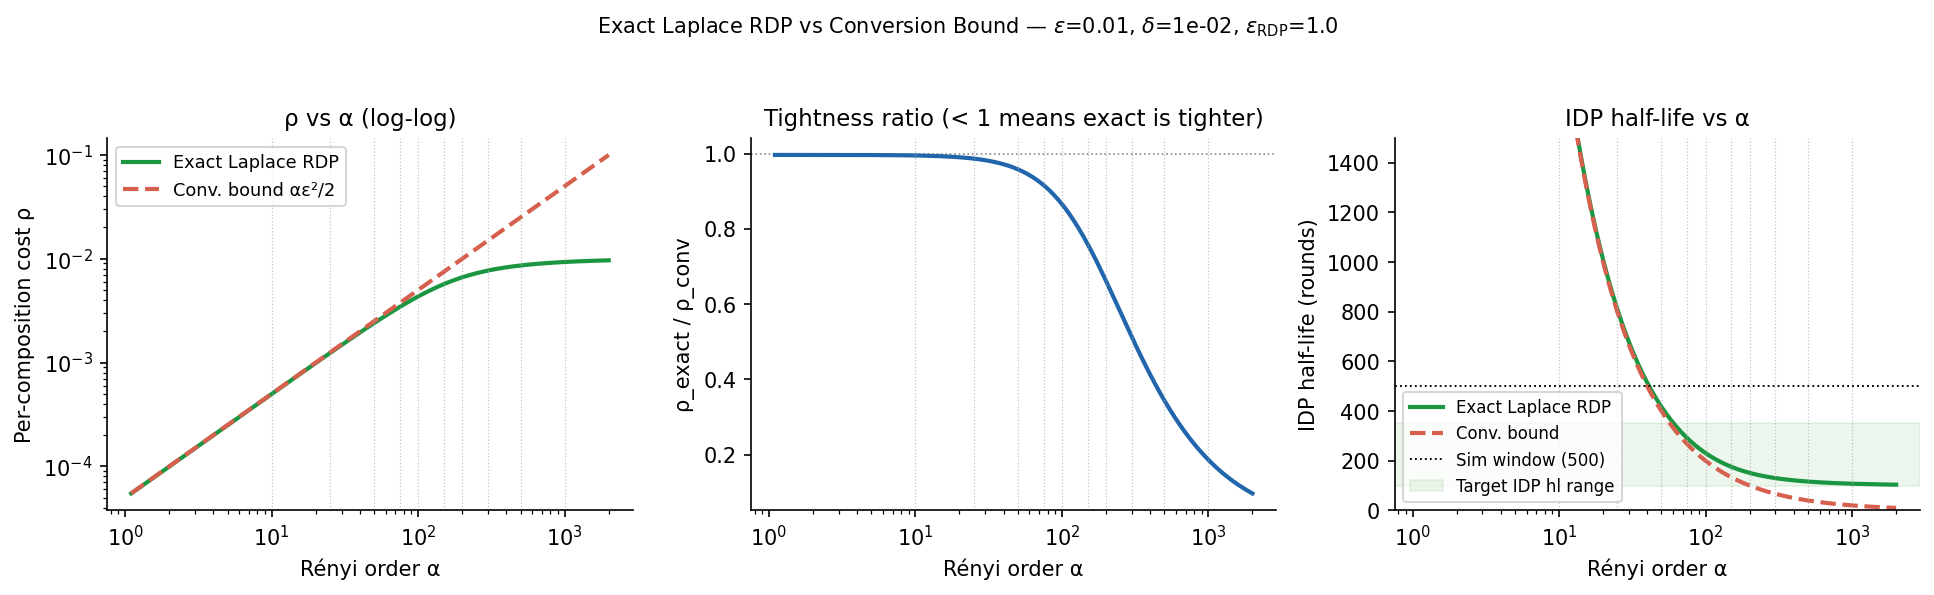

     α     ρ_exact      ρ_conv    ratio    hl_exact   hl_conv
----------------------------------------------------------
    10    0.000498    0.000500   0.9952      2009.7    2000.0
    25    0.001234    0.001250   0.9869       810.6     800.0
    50    0.002397    0.002500   0.9586       417.3     400.0
    75    0.003437    0.003750   0.9165       291.0     266.7
   100    0.004331    0.005000   0.8662       230.9     200.0
   150    0.005698    0.007500   0.7597       175.5     133.3
   200    0.006621    0.010000   0.6621       151.0     100.0
   300    0.007696    0.015000   0.5130       129.9      66.7
   500    0.008613    0.025000   0.3445       116.1      40.0
  1000    0.009307    0.050000   0.1861       107.4      20.0


In [2]:
def rho_exact_laplace(alpha, epsilon):
    """Exact RDP of Laplace(0, 1/epsilon) with sensitivity 1 at order alpha."""
    if alpha <= 1:
        raise ValueError('alpha must be > 1')
    a = alpha
    coeff_pos = a / (2*a - 1)
    coeff_neg = (a - 1) / (2*a - 1)
    log_arg = coeff_pos * math.exp((a - 1) * epsilon) + coeff_neg * math.exp(-a * epsilon)
    return math.log(log_arg) / (a - 1)

def rho_conv(alpha, epsilon):
    """Generic ε-DP → RDP conversion bound: alpha * epsilon^2 / 2."""
    return alpha * epsilon**2 / 2

alpha_fine = np.logspace(np.log10(1.1), np.log10(2000), 300)
rho_e = [rho_exact_laplace(a, EPSILON) for a in alpha_fine]
rho_c = [rho_conv(a, EPSILON) for a in alpha_fine]
ratio = [e / c for e, c in zip(rho_e, rho_c)]

# IDP half-lives under each formula
hl_exact = [EPS_RDP_BUDGET / r for r in rho_e]
hl_conv  = [EPS_RDP_BUDGET / r for r in rho_c]

fig, axes = plt.subplots(1, 3, figsize=(13, 4))

ax = axes[0]
ax.loglog(alpha_fine, rho_e, color='#1a9641', lw=2, label='Exact Laplace RDP')
ax.loglog(alpha_fine, rho_c, color='#d6604d', lw=2, linestyle='--', label='Conv. bound αε²/2')
for a in ALPHA_SWEEP:
    ax.axvline(a, color='#aaa', lw=0.6, linestyle=':', alpha=0.7)
ax.set_xlabel('Rényi order α')
ax.set_ylabel('Per-composition cost ρ')
ax.set_title('ρ vs α (log-log)')
ax.legend()

ax = axes[1]
ax.semilogx(alpha_fine, ratio, color='#2166ac', lw=2)
ax.axhline(1.0, color='#888', lw=0.8, linestyle=':', zorder=0)
for a in ALPHA_SWEEP:
    ax.axvline(a, color='#aaa', lw=0.6, linestyle=':', alpha=0.7)
ax.set_xlabel('Rényi order α')
ax.set_ylabel('ρ_exact / ρ_conv')
ax.set_title('Tightness ratio (< 1 means exact is tighter)')

ax = axes[2]
ax.semilogx(alpha_fine, hl_exact, color='#1a9641', lw=2, label='Exact Laplace RDP')
ax.semilogx(alpha_fine, hl_conv,  color='#d6604d', lw=2, linestyle='--', label='Conv. bound')
ax.axhline(N_ROUNDS, color='black', lw=0.9, linestyle=':', label=f'Sim window ({N_ROUNDS})')
ax.axhspan(100, 350, alpha=0.07, color='green', label='Target IDP hl range')
for a in ALPHA_SWEEP:
    ax.axvline(a, color='#aaa', lw=0.6, linestyle=':', alpha=0.7)
ax.set_xlabel('Rényi order α')
ax.set_ylabel('IDP half-life (rounds)')
ax.set_title('IDP half-life vs α')
ax.set_ylim(0, 1500)
ax.legend(fontsize=8)

fig.suptitle(
    rf'Exact Laplace RDP vs Conversion Bound — $\varepsilon$={EPSILON}, $\delta$={DELTA:.0e}, '
    rf'$\varepsilon_{{\mathrm{{RDP}}}}$={EPS_RDP_BUDGET}',
    fontsize=10,
)
plt.tight_layout(rect=[0, 0, 1, 0.94])
plt.savefig('../figures/alpha_sweep_rho_comparison.png', bbox_inches='tight', dpi=200)
plt.show()

print(f'{"α":>6}  {"ρ_exact":>10}  {"ρ_conv":>10}  {"ratio":>7}  {"hl_exact":>10}  {"hl_conv":>8}')
print('-' * 58)
for a in ALPHA_SWEEP:
    re_ = rho_exact_laplace(a, EPSILON)
    rc_ = rho_conv(a, EPSILON)
    print(f'{a:>6}  {re_:>10.6f}  {rc_:>10.6f}  {re_/rc_:>7.4f}  '
          f'{EPS_RDP_BUDGET/re_:>10.1f}  {EPS_RDP_BUDGET/rc_:>8.1f}')

## Section 2: Schedule Cost vs α

How does K_1·ρ (registration cost) and K_10·ρ (cost after 10 hits) scale with α?
These determine how fast users burn through their ε_RDP budget under TCT.

     α         ρ       K1·ρ       K5·ρ      K10·ρ      K20·ρ      K30·ρ
---------------------------------------------------------------
    10   0.00050     0.0122     0.0258     0.0369     0.0552     0.0715
    25   0.00125     0.0305     0.0645     0.0922     0.1379     0.1788
    50   0.00250     0.0609     0.1290     0.1844     0.2759     0.3576
    75   0.00375     0.0914     0.1935     0.2766     0.4138     0.5364
   100   0.00500     0.1218     0.2580     0.3687     0.5518     0.7152
   150   0.00750     0.1828     0.3870     0.5531     0.8277     1.0728
   200   0.01000     0.2437     0.5160     0.7375     1.1036     1.4304
   300   0.01500     0.3655     0.7740     1.1062     1.6554     2.1456
   500   0.02500     0.6092     1.2899     1.8437     2.7590     3.5761
  1000   0.05000     1.2184     2.5799     3.6875     5.5179     7.1521


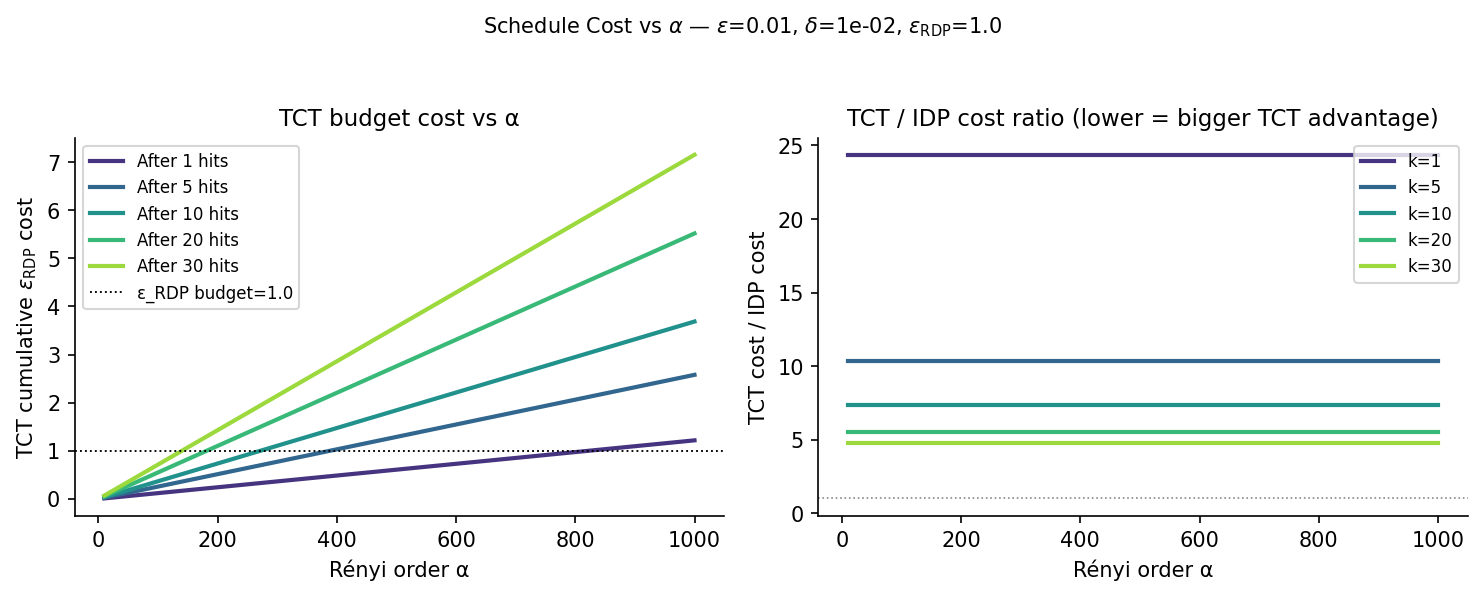

In [3]:
hit_targets = [1, 5, 10, 20, 30]

print(f'{"α":>6}  {"ρ":>8}  ' + '  '.join(f'{"K"+str(k)+"·ρ":>9}' for k in hit_targets))
print('-' * (8 + 9 * len(hit_targets) + 10))

rows = []
for a in ALPHA_SWEEP:
    acc = AdaptiveTCTAccountant(EPSILON, DELTA, alpha_rdp=a)
    rho = rho_conv(a, EPSILON)
    costs = [acc.budget_cost(acc.compositions(k)) for k in hit_targets]
    rows.append({'alpha': a, 'rho': rho, **{f'K{k}': costs[i] for i, k in enumerate(hit_targets)}})
    cost_str = '  '.join(f'{c:>9.4f}' for c in costs)
    print(f'{a:>6}  {rho:>8.5f}  {cost_str}')

df_costs = pd.DataFrame(rows)

fig, axes = plt.subplots(1, 2, figsize=(10, 4))

colors = cm.viridis(np.linspace(0.15, 0.85, len(hit_targets)))

ax = axes[0]
for i, k in enumerate(hit_targets):
    ax.plot(df_costs['alpha'], df_costs[f'K{k}'], color=colors[i], lw=2, label=f'After {k} hits')
ax.axhline(EPS_RDP_BUDGET, color='black', lw=0.9, linestyle=':', label=f'ε_RDP budget={EPS_RDP_BUDGET}')
ax.set_xlabel('Rényi order α')
ax.set_ylabel(r'TCT cumulative $\varepsilon_{\mathrm{RDP}}$ cost')
ax.set_title('TCT budget cost vs α')
ax.legend(fontsize=8)

ax = axes[1]
idp_costs = [k * rho_conv(a, EPSILON) for k in hit_targets for a in ALPHA_SWEEP]
for i, k in enumerate(hit_targets):
    tct_c = df_costs[f'K{k}'].values
    idp_c = np.array([k * rho_conv(a, EPSILON) for a in ALPHA_SWEEP])
    ax.plot(df_costs['alpha'], tct_c / idp_c, color=colors[i], lw=2, label=f'k={k}')
ax.axhline(1.0, color='#888', lw=0.8, linestyle=':', zorder=0)
ax.set_xlabel('Rényi order α')
ax.set_ylabel('TCT cost / IDP cost')
ax.set_title('TCT / IDP cost ratio (lower = bigger TCT advantage)')
ax.legend(fontsize=8)

fig.suptitle(
    rf'Schedule Cost vs $\alpha$ — $\varepsilon$={EPSILON}, $\delta$={DELTA:.0e}, '
    rf'$\varepsilon_{{\mathrm{{RDP}}}}$={EPS_RDP_BUDGET}',
    fontsize=10,
)
plt.tight_layout(rect=[0, 0, 1, 0.94])
plt.savefig('../figures/alpha_sweep_schedule_cost.png', bbox_inches='tight', dpi=200)
plt.show()

## Section 3: H1 Simulation Sweep

Run S1 (full participation, no interleaving) for each α and record half-lives.
Both TCT (Zeta-2) and IDP use ρ = α·ε²/2 so the results are directly comparable.

In [4]:
pop_cfg = PopulationConfig(
    n_users=N_USERS, alpha=0.5, beta=2.0,
    epsilon_budget=EPS_RDP_BUDGET, delta_budget=1.0,
)

def calibrate(pop_cfg, seed=SEED):
    rng = np.random.default_rng(seed)
    pop = generate_synthetic_population(pop_cfg, rng=np.random.default_rng(seed))
    noisy = []
    for _ in range(3000):
        parts = list(pop.active_users)
        cnt, _ = compute_round_conversions(parts, rng)
        noisy.append(cnt + rng.laplace(0, 1/EPSILON))
    return float(np.quantile(noisy, 1 - TARGET_HIT))

def run_s1(accountant_factory, T, seed=SEED):
    rng = np.random.default_rng(seed)
    pop = generate_synthetic_population(pop_cfg, rng=np.random.default_rng(seed))
    acc = accountant_factory()
    frac = []
    for r in range(N_ROUNDS):
        active = pop.active_users
        if not active: break
        parts = list(active)
        cnt, contribs = compute_round_conversions(parts, rng)
        is_top, _ = laplace_threshold_query(cnt, T, EPSILON, rng)
        for i, user in enumerate(parts):
            e, d = acc.charge(user=user, is_top=is_top,
                              contributed=contribs[i], round_num=r)
            user.epsilon_spent += e
            user.delta_spent   += d
        pop.drop_depleted()
        frac.append(pop.active_fraction)
    return frac

def half_life(frac):
    for r, f in enumerate(frac):
        if f <= 0.5: return r
    return len(frac)

print('Calibrating threshold...')
T = calibrate(pop_cfg)
print(f'T = {T:.2f}')
print()
print('Running H1 S1 sweep...')

results = []
all_fracs = {}
for alpha in ALPHA_SWEEP:
    rho = rho_conv(alpha, EPSILON)
    frac_tct = run_s1(lambda a=alpha: AdaptiveTCTAccountant(
        EPSILON, DELTA, alpha_rdp=a, schedule='zeta2', independent=True), T)
    frac_idp = run_s1(lambda r=rho: StandardDPAccountant(r), T)
    hl_tct = half_life(frac_tct)
    hl_idp = half_life(frac_idp)
    results.append({
        'alpha': alpha, 'rho': rho,
        'hl_tct': hl_tct, 'hl_idp': hl_idp,
        'advantage': hl_tct - hl_idp,
        'hl_idp_theory': EPS_RDP_BUDGET / rho,
    })
    all_fracs[alpha] = (frac_tct, frac_idp)
    print(f'  α={alpha:>5}  ρ={rho:.5f}  TCT hl={hl_tct:>4}  IDP hl={hl_idp:>4}  adv=+{hl_tct-hl_idp}')

df = pd.DataFrame(results)

Calibrating threshold...


T = 1318.27

Running H1 S1 sweep...


  α=   10  ρ=0.00050  TCT hl= 500  IDP hl= 500  adv=+0


  α=   25  ρ=0.00125  TCT hl= 500  IDP hl= 500  adv=+0


  α=   50  ρ=0.00250  TCT hl= 500  IDP hl= 400  adv=+100


  α=   75  ρ=0.00375  TCT hl= 500  IDP hl= 266  adv=+234


  α=  100  ρ=0.00500  TCT hl= 500  IDP hl= 199  adv=+301


  α=  150  ρ=0.00750  TCT hl= 500  IDP hl= 133  adv=+367


  α=  200  ρ=0.01000  TCT hl= 500  IDP hl=  99  adv=+401


  α=  300  ρ=0.01500  TCT hl= 500  IDP hl=  66  adv=+434


  α=  500  ρ=0.02500  TCT hl= 500  IDP hl=  39  adv=+461
  α= 1000  ρ=0.05000  TCT hl=   0  IDP hl=  19  adv=+-19


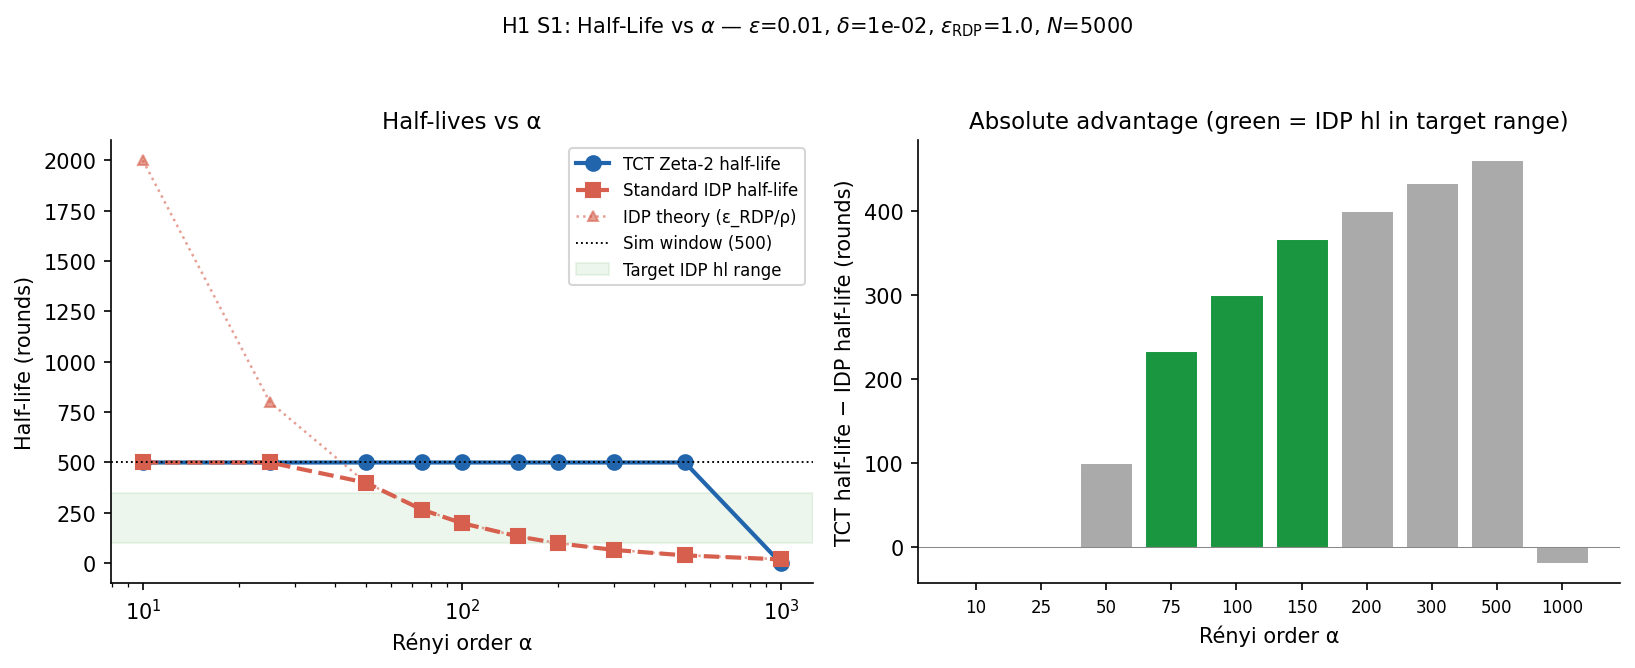

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))

# Panel 1: half-lives vs alpha
ax = axes[0]
ax.plot(df['alpha'], df['hl_tct'], 'o-', color='#2166ac', lw=2, ms=7, label='TCT Zeta-2 half-life')
ax.plot(df['alpha'], df['hl_idp'], 's--', color='#d6604d', lw=2, ms=7, label='Standard IDP half-life')
ax.plot(df['alpha'], df['hl_idp_theory'], '^:', color='#d6604d', lw=1.2, ms=5, alpha=0.6,
        label='IDP theory (ε_RDP/ρ)')
ax.axhline(N_ROUNDS, color='black', lw=0.9, linestyle=':', label=f'Sim window ({N_ROUNDS})')
ax.axhspan(100, 350, alpha=0.07, color='green', label='Target IDP hl range')
ax.set_xlabel('Rényi order α')
ax.set_ylabel('Half-life (rounds)')
ax.set_title('Half-lives vs α')
ax.set_xscale('log')
ax.legend(fontsize=8, loc='upper right')

# Panel 2: absolute advantage (hl_tct - hl_idp)
ax = axes[1]
bar_colors = ['#1a9641' if 100 <= r['hl_idp'] <= 350 else '#aaa' for _, r in df.iterrows()]
ax.bar(range(len(df)), df['advantage'], color=bar_colors, edgecolor='white', linewidth=0.5)
ax.set_xticks(range(len(df)))
ax.set_xticklabels([str(a) for a in df['alpha']], fontsize=8)
ax.set_xlabel('Rényi order α')
ax.set_ylabel('TCT half-life − IDP half-life (rounds)')
ax.set_title('Absolute advantage (green = IDP hl in target range)')
ax.axhline(0, color='#888', lw=0.5)

fig.suptitle(
    rf'H1 S1: Half-Life vs $\alpha$ — $\varepsilon$={EPSILON}, $\delta$={DELTA:.0e}, '
    rf'$\varepsilon_{{\mathrm{{RDP}}}}$={EPS_RDP_BUDGET}, $N$={N_USERS}',
    fontsize=10,
)
plt.tight_layout(rect=[0, 0, 1, 0.94])
plt.savefig('../figures/alpha_sweep_halflife.png', bbox_inches='tight', dpi=200)
plt.show()

## Section 4: Retention Curves for Selected α Values

Plot the full retention curves for the α values where IDP half-life falls in the target window.

Target α values (IDP hl in 100-350): [np.float64(75.0), np.float64(100.0), np.float64(150.0)]


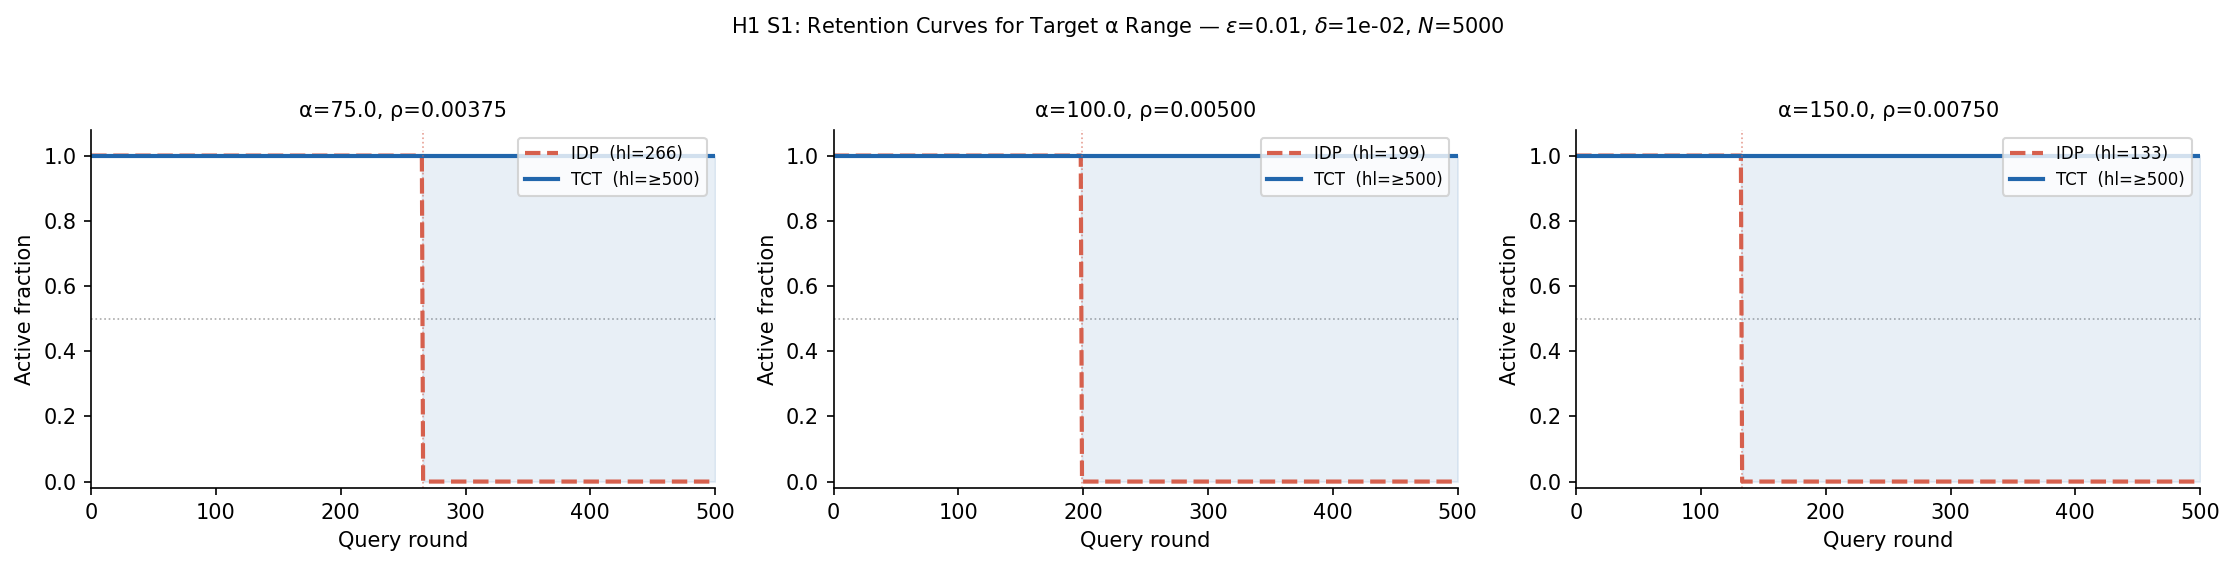

In [6]:
# Select alphas where IDP half-life is in target window (100-350 rounds)
target_alphas = [r['alpha'] for _, r in df.iterrows() if 100 <= r['hl_idp'] <= 350]
print(f'Target α values (IDP hl in 100-350): {target_alphas}')

n_plots = len(target_alphas)
ncols = min(3, n_plots)
nrows = math.ceil(n_plots / ncols)
fig, axes = plt.subplots(nrows, ncols, figsize=(5*ncols, 3.8*nrows), squeeze=False)

def pad(c, n):
    return list(c) + [c[-1] if c else 0.0] * (n - len(c))

for idx, alpha in enumerate(target_alphas):
    ax = axes[idx // ncols][idx % ncols]
    frac_tct, frac_idp = all_fracs[alpha]
    row = df[df['alpha'] == alpha].iloc[0]
    hl_tct = int(row['hl_tct']); hl_idp = int(row['hl_idp'])
    rho = row['rho']
    
    n = max(len(frac_tct), len(frac_idp)) + 1
    rnds = list(range(n))
    ta = pad(frac_tct, n); ia = pad(frac_idp, n)
    sat = hl_tct >= n - 2
    
    ax.plot(rnds, ia, color='#d6604d', lw=2, linestyle='--',
            label=f'IDP  (hl={hl_idp})')
    ax.plot(rnds, ta, color='#2166ac', lw=2,
            label=f'TCT  (hl={"≥"+str(hl_tct) if sat else str(hl_tct)})')
    ax.fill_between(rnds, ia, ta, alpha=0.10, color='#2166ac')
    ax.axhline(0.5, color='#aaa', lw=0.8, linestyle=':', zorder=0)
    if hl_idp < n - 2:
        ax.axvline(hl_idp, color='#d6604d', lw=0.8, linestyle=':', alpha=0.6)
    ax.set_xlabel('Query round')
    ax.set_ylabel('Active fraction')
    ax.set_title(rf'α={alpha}, ρ={rho:.5f}', fontsize=10)
    ax.set_xlim(0, n-1); ax.set_ylim(-0.02, 1.08)
    ax.legend(loc='upper right', fontsize=8)

# Hide unused axes
for idx in range(len(target_alphas), nrows * ncols):
    axes[idx // ncols][idx % ncols].set_visible(False)

fig.suptitle(
    rf'H1 S1: Retention Curves for Target α Range — '
    rf'$\varepsilon$={EPSILON}, $\delta$={DELTA:.0e}, $N$={N_USERS}',
    fontsize=10,
)
plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.savefig('../figures/alpha_sweep_retention_curves.png', bbox_inches='tight', dpi=200)
plt.show()

## Section 5: Exact RDP — How Much Does α Choice Matter?

Re-run the sweep using the exact Laplace RDP formula instead of the conversion bound.
Under the exact formula, lower α gives a tighter (smaller) ρ, potentially shifting all half-lives.

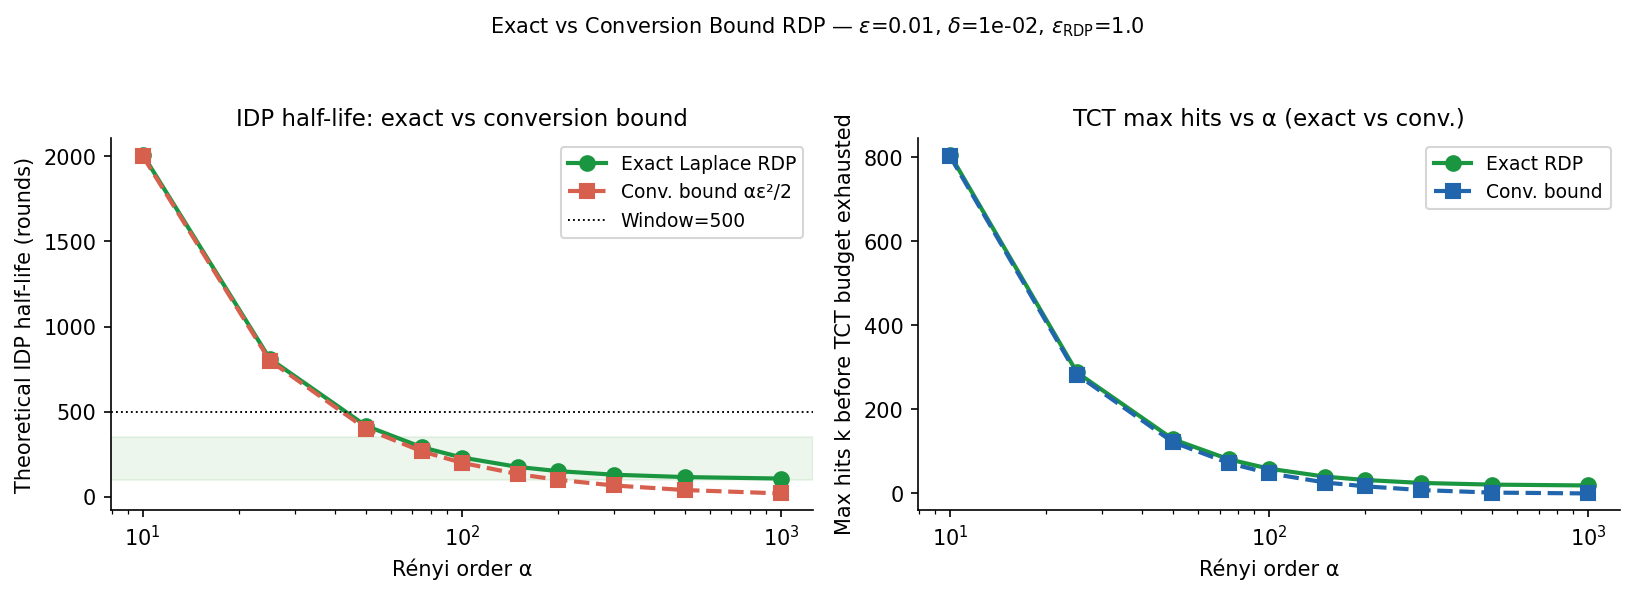

     α     ρ_exact      ρ_conv   tightness   hl_idp_ex   hl_idp_cv   hits_ex   hits_cv
----------------------------------------------------------------------------------
    10    0.000498    0.000500      0.9952      2009.7      2000.0       807       803
    25    0.001234    0.001250      0.9869       810.6       800.0       288       283
    50    0.002397    0.002500      0.9586       417.3       400.0       129       122
    75    0.003437    0.003750      0.9165       291.0       266.7        81        72
   100    0.004331    0.005000      0.8662       230.9       200.0        59        48
   150    0.005698    0.007500      0.7597       175.5       133.3        40        26
   200    0.006621    0.010000      0.6621       151.0       100.0        32        17
   300    0.007696    0.015000      0.5130       129.9        66.7        25         8
   500    0.008613    0.025000      0.3445       116.1        40.0        21         2
  1000    0.009307    0.050000      0.1861     

In [7]:
# Under exact RDP, IDP charges rho_exact per round.
# TCT still uses the K_k schedule (based on conversion bound — standard practice).
# This isolates the effect of the per-composition cost formula on half-lives.

results_exact = []
for alpha in ALPHA_SWEEP:
    rho_e_ = rho_exact_laplace(alpha, EPSILON)
    rho_c_ = rho_conv(alpha, EPSILON)
    # IDP half-life under exact formula
    hl_idp_exact_theory = EPS_RDP_BUDGET / rho_e_
    # TCT half-life: K_k * rho_exact (instead of K_k * rho_conv)
    acc = AdaptiveTCTAccountant(EPSILON, DELTA, alpha_rdp=alpha)
    # Find max k such that K_{k+1} * rho_exact <= budget
    k_max = 0
    for k in range(1, 1000):
        if acc.compositions(k) * rho_e_ > EPS_RDP_BUDGET:
            k_max = k - 1
            break
    else:
        k_max = 999
    results_exact.append({
        'alpha': alpha,
        'rho_exact': rho_e_, 'rho_conv': rho_c_,
        'ratio': rho_e_ / rho_c_,
        'hl_idp_exact': hl_idp_exact_theory,
        'hl_idp_conv': EPS_RDP_BUDGET / rho_c_,
        'max_hits_tct_exact': k_max,
        'max_hits_tct_conv': next((k-1 for k in range(1,1000)
                                   if acc.compositions(k)*rho_c_ > EPS_RDP_BUDGET), 999),
    })

df_ex = pd.DataFrame(results_exact)

fig, axes = plt.subplots(1, 2, figsize=(11, 4))

ax = axes[0]
ax.semilogx(df_ex['alpha'], df_ex['hl_idp_exact'], 'o-', color='#1a9641', lw=2, ms=7,
            label='Exact Laplace RDP')
ax.semilogx(df_ex['alpha'], df_ex['hl_idp_conv'],  's--', color='#d6604d', lw=2, ms=7,
            label='Conv. bound αε²/2')
ax.axhline(N_ROUNDS, color='black', lw=0.9, linestyle=':', label=f'Window={N_ROUNDS}')
ax.axhspan(100, 350, alpha=0.07, color='green')
ax.set_xlabel('Rényi order α')
ax.set_ylabel('Theoretical IDP half-life (rounds)')
ax.set_title('IDP half-life: exact vs conversion bound')
ax.legend(fontsize=9)

ax = axes[1]
ax.semilogx(df_ex['alpha'], df_ex['max_hits_tct_exact'], 'o-', color='#1a9641', lw=2, ms=7,
            label='Exact RDP')
ax.semilogx(df_ex['alpha'], df_ex['max_hits_tct_conv'],  's--', color='#2166ac', lw=2, ms=7,
            label='Conv. bound')
ax.set_xlabel('Rényi order α')
ax.set_ylabel('Max hits k before TCT budget exhausted')
ax.set_title('TCT max hits vs α (exact vs conv.)')
ax.legend(fontsize=9)

fig.suptitle(
    rf'Exact vs Conversion Bound RDP — $\varepsilon$={EPSILON}, $\delta$={DELTA:.0e}, '
    rf'$\varepsilon_{{\mathrm{{RDP}}}}$={EPS_RDP_BUDGET}',
    fontsize=10,
)
plt.tight_layout(rect=[0, 0, 1, 0.94])
plt.savefig('../figures/alpha_sweep_exact_vs_conv.png', bbox_inches='tight', dpi=200)
plt.show()

print(f'{"α":>6}  {"ρ_exact":>10}  {"ρ_conv":>10}  {"tightness":>10}  '
      f'{"hl_idp_ex":>10}  {"hl_idp_cv":>10}  {"hits_ex":>8}  {"hits_cv":>8}')
print('-' * 82)
for _, r in df_ex.iterrows():
    print(f'{int(r["alpha"]):>6}  {r["rho_exact"]:>10.6f}  {r["rho_conv"]:>10.6f}  '
          f'{r["ratio"]:>10.4f}  {r["hl_idp_exact"]:>10.1f}  {r["hl_idp_conv"]:>10.1f}  '
          f'{int(r["max_hits_tct_exact"]):>8}  {int(r["max_hits_tct_conv"]):>8}')

## Section 6: Recommendation

In [8]:
print('=== Alpha Selection Summary ===')
print(f'ε={EPSILON}, δ={DELTA:.0e}, ε_RDP={EPS_RDP_BUDGET}, N_ROUNDS={N_ROUNDS}')
print()
print('Simulation results (S1: full participation, no interleaving):')
print(f'{"α":>6}  {"ρ":>8}  {"IDP hl":>7}  {"TCT hl":>7}  {"adv":>6}  {"verdict"}')
print('-' * 60)
for _, r in df.iterrows():
    a  = int(r['alpha'])
    hl_i = int(r['hl_idp']); hl_t = int(r['hl_tct'])
    adv = hl_t - hl_i
    if hl_i > N_ROUNDS:
        verdict = 'IDP does not exhaust in window'
    elif hl_i < 50:
        verdict = 'IDP exhausts too fast'
    elif hl_t >= N_ROUNDS - 2:
        verdict = f'GOOD — TCT hl ≥{N_ROUNDS}, adv clearly visible'
    else:
        verdict = f'OK — adv +{adv} rounds'
    print(f'{a:>6}  {r["rho"]:>8.5f}  {hl_i:>7}  {hl_t:>7}  {adv:>6}  {verdict}')

best_row = df[df['hl_idp'].between(100, 350)].copy()
if len(best_row) > 0:
    # Prefer the α where TCT half-life is highest (most advantage)
    best_row = best_row.loc[best_row['hl_tct'].idxmax()]
    print()
    print(f'Recommended α = {int(best_row["alpha"])}')
    print(f'  ρ = {best_row["rho"]:.5f}')
    print(f'  IDP half-life = {int(best_row["hl_idp"])} rounds (theory: {best_row["hl_idp_theory"]:.0f})')
    print(f'  TCT half-life = {int(best_row["hl_tct"])} rounds')
    print(f'  Advantage     = +{int(best_row["advantage"])} rounds')
    print()
    print('Note: the exact Laplace RDP formula gives tighter ρ values.')
    exact_rho = rho_exact_laplace(int(best_row['alpha']), EPSILON)
    print(f'  ρ_exact({int(best_row["alpha"])}) = {exact_rho:.6f}  vs  ρ_conv = {best_row["rho"]:.6f}')
    print(f'  Using exact RDP would give IDP hl ≈ {EPS_RDP_BUDGET/exact_rho:.0f} rounds')
    print(f'  (tighter by {100*(1 - exact_rho/best_row["rho"]):.1f}%)')

=== Alpha Selection Summary ===
ε=0.01, δ=1e-02, ε_RDP=1.0, N_ROUNDS=500

Simulation results (S1: full participation, no interleaving):
     α         ρ   IDP hl   TCT hl     adv  verdict
------------------------------------------------------------
    10   0.00050      500      500       0  GOOD — TCT hl ≥500, adv clearly visible
    25   0.00125      500      500       0  GOOD — TCT hl ≥500, adv clearly visible
    50   0.00250      400      500     100  GOOD — TCT hl ≥500, adv clearly visible
    75   0.00375      266      500     234  GOOD — TCT hl ≥500, adv clearly visible
   100   0.00500      199      500     301  GOOD — TCT hl ≥500, adv clearly visible
   150   0.00750      133      500     367  GOOD — TCT hl ≥500, adv clearly visible
   200   0.01000       99      500     401  GOOD — TCT hl ≥500, adv clearly visible
   300   0.01500       66      500     434  GOOD — TCT hl ≥500, adv clearly visible
   500   0.02500       39      500     461  IDP exhausts too fast
  1000   0.05